# Experiment 04 - Simple CNN Model With AVG Pooling
## Model Architecture

In this experiment, we use the same `SimpleCNN` architecture as the baseline model, with one controlled change: the pooling operation.

The model consists of:

- **Convolutional layer:** `3 → 32` channels
- **ReLU activation**
- **Pooling layer:** Max Pooling or Average Pooling
- **Convolutional layer:** `32 → 64` channels
- **ReLU activation**
- **Pooling layer:** Max Pooling or Average Pooling
- **Flatten**
- **Fully connected layer:** `64 × 56 × 56 → 128`
- **ReLU activation**
- **Dropout:** `p = 0.0`
- **Output layer:** `128 → 8` classes

For the Max Pooling(Baseline) model, `MaxPool2d(2)` is used, while the Average Pooling model uses `AvgPool2d(2)`.

All other components and training settings are kept the same so that the effect of the pooling method can be compared fairly.

In [40]:
import sys
from pathlib import Path
from torchvision import datasets
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import math
from collections import Counter
import json

from torch.optim import Adam
from torchvision import transforms

from sklearn.metrics import classification_report

# Project root
PROJECT_DIR = Path.cwd().parent

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

sys.path.append("../src")

from data import (
    letterbox,
    create_train_val_datasets,
    create_dataloaders
)

from models import SimpleCNNAvgPool

from train import train_model

from utils import (
    get_predictions,
    plot_confusion_matrix,
    get_classification_report,
    plot_training_history,
    set_seed
)

### Configuration

In [ ]:
SEED = 42
set_seed(SEED)
BATCH_SIZE = 32
EPOCHS = 10
LEARNING_RATE = 1e-3
NUM_CLASSES = 8


config = {
    "model": "SimpleCNNAvgPool",
    "experiment": "AvgPool2d",
    "num_classes": NUM_CLASSES,
    "dropout": 0.0,
    "use_gap": False,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "epochs": EPOCHS,
    "train_transform": [
        "LetterBox",
        "Resize(224,224)",
        "ToTensor",
        "Normalize"
    ],

    "val_transform": [
        "LetterBox",
        "Resize(224,224)",
        "ToTensor",
        "Normalize"
    ]
}

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

Device: cpu


### Paths

In [20]:
MERGED_TRAIN_DIR = PROJECT_DIR / "dataset" / "merged_train"
TEST_DIR = PROJECT_DIR / "dataset" / "test"

print("Training directory:", MERGED_TRAIN_DIR)
print("Test directory:", TEST_DIR)

print("Training directory exists:", MERGED_TRAIN_DIR.exists())
print("Test directory exists:", TEST_DIR.exists())

Training directory: d:\AI Bootcamp_M Sharif\traffic_vehicle_project\dataset\merged_train
Test directory: d:\AI Bootcamp_M Sharif\traffic_vehicle_project\dataset\test
Training directory exists: True
Test directory exists: True


### Tranforms as the Baseline Model

In [21]:
baseline_transform = transforms.Compose([
    transforms.Lambda(
        lambda img: letterbox(
            img,
            target_size=(224, 224)
        )
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

### Create Train/Validation Datasets

In [22]:
train_dataset, val_dataset, train_indices, val_indices,class_to_idx= \
    create_train_val_datasets(
        data_dir=MERGED_TRAIN_DIR,
        train_transform=baseline_transform,
        val_transform=baseline_transform,
        test_size=0.2,
        seed=SEED
    )

### Class Names

In [23]:
full_dataset = datasets.ImageFolder(
    MERGED_TRAIN_DIR
)

class_names = full_dataset.classes
class_to_idx = full_dataset.class_to_idx

print("Classes:")
for index, class_name in enumerate(class_names):
    print(index, "->", class_name)

print("\nNumber of classes:", len(class_names))

Classes:
0 -> ambulance
1 -> autobus
2 -> kamyun
3 -> kamyunet
4 -> minibus
5 -> savari
6 -> taxi
7 -> vanet

Number of classes: 8


### Dataset Size

In [24]:
train_class_counts = Counter(
    full_dataset.targets[i]
    for i in train_indices
)

val_class_counts = Counter(
    full_dataset.targets[i]
    for i in val_indices
)

print("Class distribution:")
print()

for class_index, class_name in enumerate(class_names):
    train_count = train_class_counts[class_index]
    val_count = val_class_counts[class_index]

    print(
        f"{class_index} -> {class_name}: "
        f"Train = {train_count} ({train_count / len(train_dataset):.1%}), "
        f"Validation = {val_count} ({val_count / len(val_dataset):.1%})"
    )

print("Total training samples:", len(train_dataset) + len(val_dataset))
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))

Class distribution:

0 -> ambulance: Train = 289 (9.2%), Validation = 72 (9.1%)
1 -> autobus: Train = 376 (11.9%), Validation = 94 (11.9%)
2 -> kamyun: Train = 397 (12.6%), Validation = 99 (12.6%)
3 -> kamyunet: Train = 364 (11.6%), Validation = 91 (11.6%)
4 -> minibus: Train = 328 (10.4%), Validation = 82 (10.4%)
5 -> savari: Train = 400 (12.7%), Validation = 100 (12.7%)
6 -> taxi: Train = 394 (12.5%), Validation = 99 (12.6%)
7 -> vanet: Train = 599 (19.0%), Validation = 150 (19.1%)
Total training samples: 3934
Training samples: 3147
Validation samples: 787


### DataLoaders

In [25]:
train_loader, val_loader = create_dataloaders(
    train_dataset=train_dataset,
    val_dataset=val_dataset,
    batch_size=BATCH_SIZE,
    shuffle_train=True
)

print("Number of training batches:", len(train_loader))
print("Number of validation batches:", len(val_loader))

Number of training batches: 99
Number of validation batches: 25


### Checking one Batch

Images shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])
Labels: tensor([7, 6, 0, 0, 2, 6, 4, 6, 5, 7, 1, 6, 5, 2, 5, 2, 7, 3, 1, 2, 5, 3, 3, 2,
        5, 6, 2, 6, 5, 0, 7, 5])


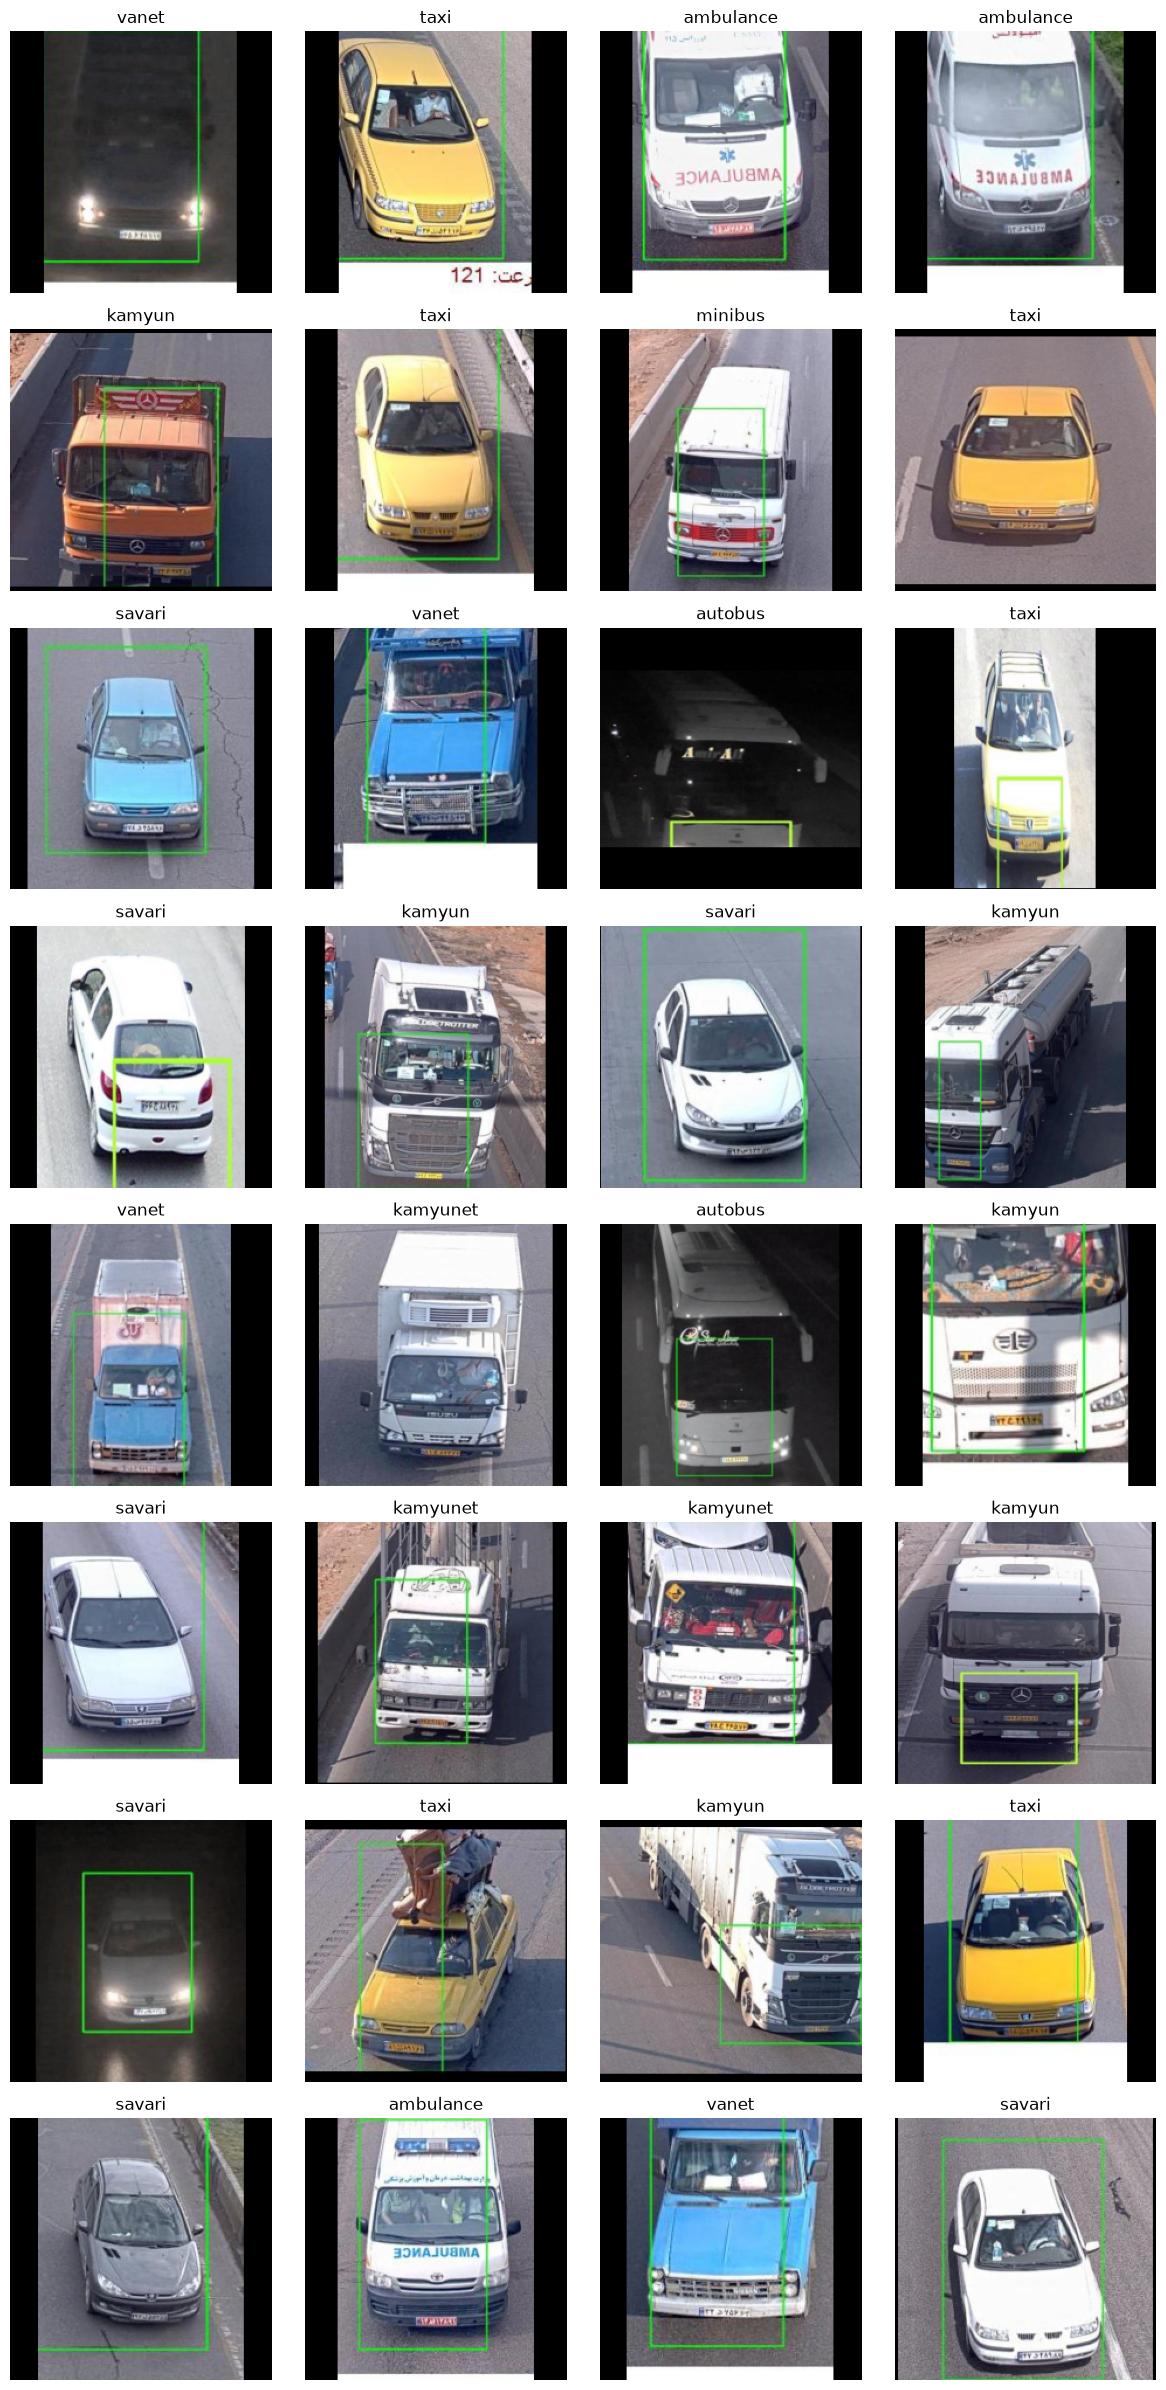

In [26]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Labels:", labels)

# ImageNet normalization values
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

num_images = len(images)
cols = 4
rows = math.ceil(num_images / cols)

plt.figure(figsize=(12, 3 * rows))

for i in range(num_images):
    # Denormalize
    image = images[i] * std + mean

    # CHW -> HWC
    image = image.permute(1, 2, 0)

    # Keep values in valid display range
    image = image.clamp(0, 1)

    plt.subplot(rows, cols, i + 1)
    plt.imshow(image)
    plt.title(class_names[labels[i].item()])
    plt.axis("off")

plt.tight_layout()
plt.show()

### Average Pooling CNN Model

In [27]:
avg_model = SimpleCNNAvgPool(
    num_classes=NUM_CLASSES,
    dropout=0.0,
    use_gap=False
)

avg_model = avg_model.to(DEVICE)

print(avg_model)

SimpleCNNAvgPool(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): AvgPool2d(kernel_size=2, stride=2, padding=0)
  )
  (pool): Identity()
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=200704, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.0, inplace=False)
    (4): Linear(in_features=128, out_features=8, bias=True)
  )
)


### Loss and Optimizer

In [28]:
criterion = nn.CrossEntropyLoss()

optimizer = Adam(
    avg_model.parameters(),
    lr=LEARNING_RATE
)

### Training

In [29]:
history, best_val_accuracy = train_model(
    model=avg_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    device=DEVICE,
    epochs=EPOCHS,
    model_name="avg_pooling",
    class_to_idx=class_to_idx,
    seed=SEED,
    config=config
)
print("Best validation accuracy:", best_val_accuracy)

Epoch [1/10] Train Loss: 1.6333 --- Train Acc: 0.5154 --- Val Loss: 0.8867 --- Val Acc: 0.7141
Epoch [2/10] Train Loss: 0.6904 --- Train Acc: 0.7690 --- Val Loss: 0.7260 --- Val Acc: 0.7395
Epoch [3/10] Train Loss: 0.4010 --- Train Acc: 0.8653 --- Val Loss: 0.6939 --- Val Acc: 0.7687
Epoch [4/10] Train Loss: 0.2054 --- Train Acc: 0.9352 --- Val Loss: 0.7767 --- Val Acc: 0.7903
Epoch [5/10] Train Loss: 0.0920 --- Train Acc: 0.9714 --- Val Loss: 0.8714 --- Val Acc: 0.7700
Epoch [6/10] Train Loss: 0.1004 --- Train Acc: 0.9746 --- Val Loss: 1.0280 --- Val Acc: 0.7814
Epoch [7/10] Train Loss: 0.0961 --- Train Acc: 0.9692 --- Val Loss: 0.9489 --- Val Acc: 0.7687
Epoch [8/10] Train Loss: 0.0296 --- Train Acc: 0.9898 --- Val Loss: 1.1559 --- Val Acc: 0.7764
Epoch [9/10] Train Loss: 0.0208 --- Train Acc: 0.9943 --- Val Loss: 1.0530 --- Val Acc: 0.7891
Epoch [10/10] Train Loss: 0.0448 --- Train Acc: 0.9892 --- Val Loss: 1.1068 --- Val Acc: 0.7891

Best checkpoint saved:
D:\AI Bootcamp_M Sharif\t

### Training Curves

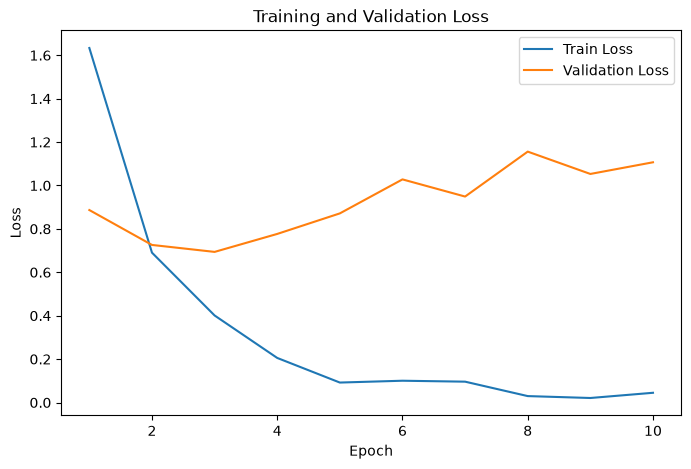

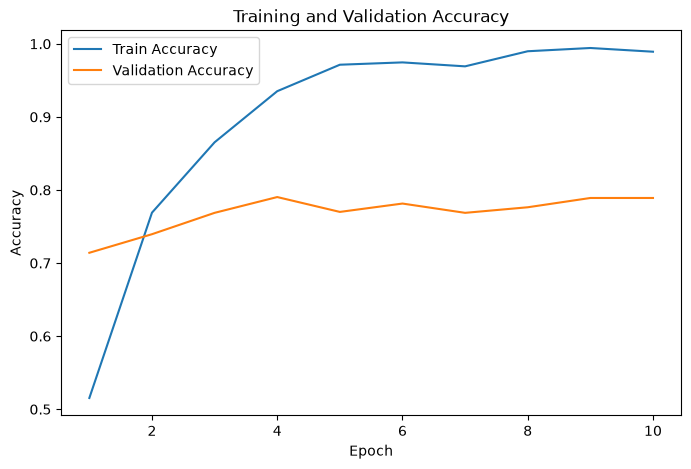

In [30]:
plot_training_history(history=history)

### Best Epoch

In [31]:
avg_best_epoch = np.argmax(
    history["val_accuracy"]
) + 1

print("Best epoch:", avg_best_epoch)
print("Best validation accuracy:", best_val_accuracy)

Best epoch: 4
Best validation accuracy: 0.7903430749682337


### Load Best Checkpoint

In [32]:
checkpoint_path = (
    PROJECT_DIR
    / "checkpoints"
    / "avg_pooling_best.pt"
)


checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

print("Best epoch:", checkpoint["epoch"])
print(
    "Best validation accuracy:",
    checkpoint["val_accuracy"]
)

Best epoch: 4
Best validation accuracy: 0.7903430749682337


### Validation Prediction

In [33]:
true_labels, predictions = get_predictions(
    model=model,
    loader=val_loader,
    device=DEVICE
)

print("Number of  validation predictions:", len(predictions))
correct = (true_labels == predictions).sum()
print("Number of correct validation predictions:", correct)
accuracy = correct / len(predictions)
print("Validation accuracy:", accuracy)

Number of  validation predictions: 787
Number of correct validation predictions: 622
Validation accuracy: 0.7903430749682337


### Classification Report

In [34]:
report = get_classification_report(
    model=model,
    loader=val_loader,
    class_names=class_names,
    device=DEVICE
)

              precision    recall  f1-score   support

   ambulance     0.6932    0.8472    0.7625        72
     autobus     0.8812    0.9468    0.9128        94
      kamyun     0.6311    0.6566    0.6436        99
    kamyunet     0.6310    0.5824    0.6057        91
     minibus     0.9077    0.7195    0.8027        82
      savari     0.7414    0.8600    0.7963       100
        taxi     0.9208    0.9394    0.9300        99
       vanet     0.8992    0.7733    0.8315       150

    accuracy                         0.7903       787
   macro avg     0.7882    0.7907    0.7856       787
weighted avg     0.7970    0.7903    0.7901       787



### Confusion Matrix

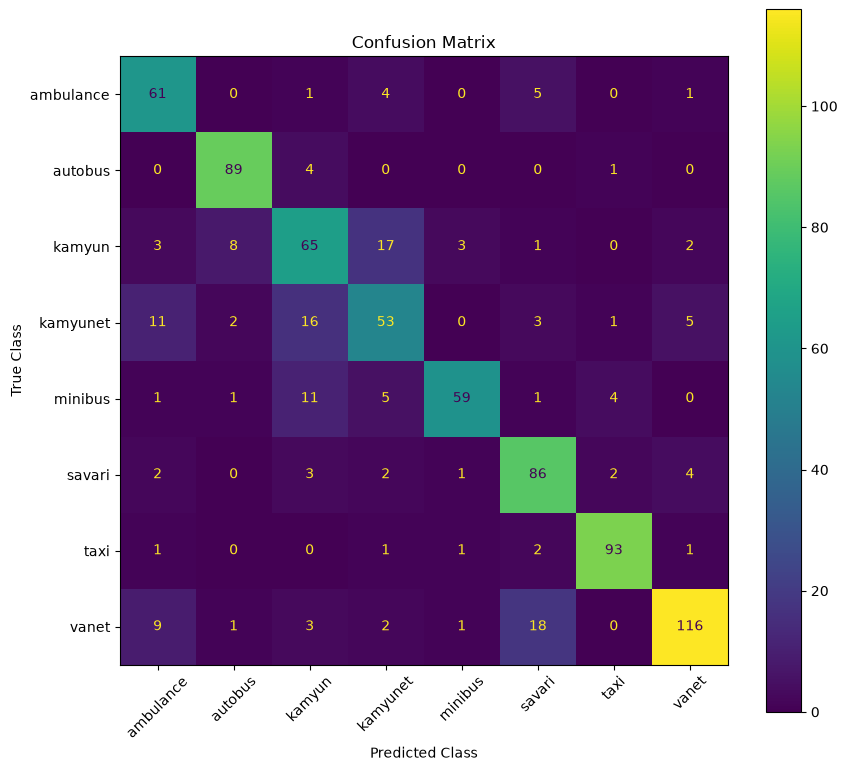

In [35]:
cm = plot_confusion_matrix(
    model=model,
    loader=val_loader,
    class_names=class_names,
    device=DEVICE
)

### Normalized Confusion Matrix

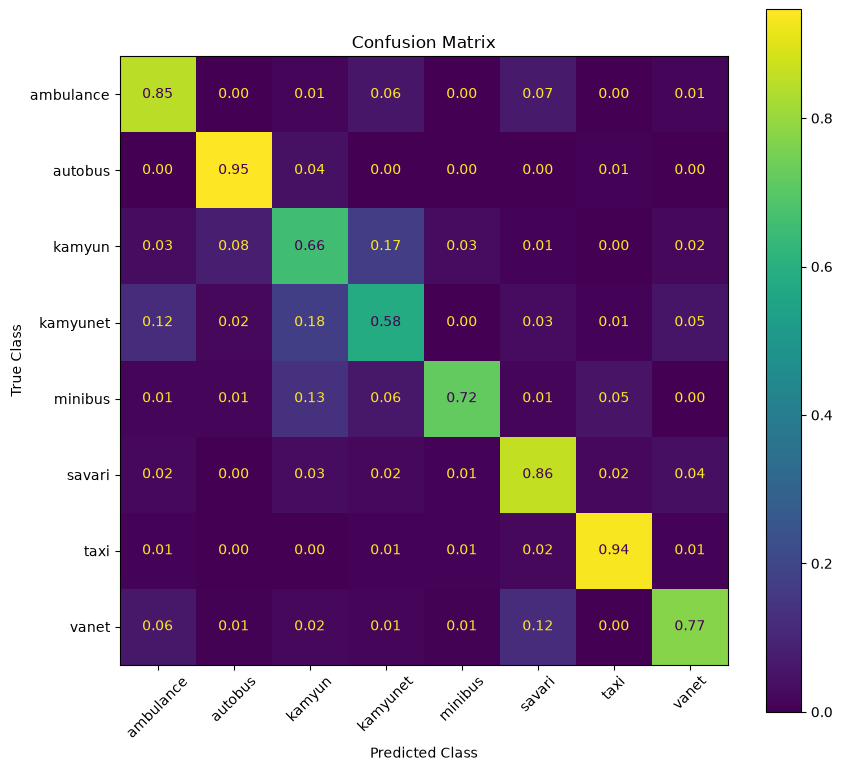

In [36]:
cm_normalized = plot_confusion_matrix(
    model=model,
    loader=val_loader,
    class_names=class_names,
    device=DEVICE,
    normalize="true"
)

### Train/Validation Gap

In [37]:
final_train_accuracy = history["train_accuracy"][-1]
final_val_accuracy = history["val_accuracy"][-1]

accuracy_gap = (
    final_train_accuracy
    - final_val_accuracy
)

print(
    "Final Train Accuracy:",
    final_train_accuracy
)

print(
    "Final Validation Accuracy:",
    final_val_accuracy
)

print(
    "Train-Validation Accuracy Gap:",
    accuracy_gap
)

Final Train Accuracy: 0.9891960597394344
Final Validation Accuracy: 0.7890724269377383
Train-Validation Accuracy Gap: 0.2001236328016961


### Avg Pooling CNN Result

In [38]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

baseline_accuracy = accuracy_score(
    true_labels,
    predictions
)

baseline_precision = precision_score(
    true_labels,
    predictions,
    average="macro",
    zero_division=0
)

baseline_recall = recall_score(
    true_labels,
    predictions,
    average="macro",
    zero_division=0
)

baseline_f1 = f1_score(
    true_labels,
    predictions,
    average="macro",
    zero_division=0
)

print("Baseline Validation Results")
print("---------------------------")
print("Accuracy:", baseline_accuracy)
print("Macro Precision:", baseline_precision)
print("Macro Recall:", baseline_recall)
print("Macro F1:", baseline_f1)

Baseline Validation Results
---------------------------
Accuracy: 0.7903430749682337
Macro Precision: 0.788184847819717
Macro Recall: 0.7906566799616229
Macro F1: 0.7856447197925132


### Final Caparison Avg Pooling VS Max Pooling

In [42]:
PROJECT_DIR = Path.cwd().parent
RESULTS_FILE = PROJECT_DIR / "results" / "experiment_results.json"

with open(RESULTS_FILE, "r", encoding="utf-8") as f:
    results = json.load(f)
    
# Average Pooling
baseline_result = results["baseline_cnn"]

print("Max Pooling Results")
print("----------------")
print("Best Epoch:", baseline_result["best_epoch"])
print("Best Validation Accuracy:", baseline_result["best_val_accuracy"])
print("Validation Loss at Best Epoch:", baseline_result["best_val_loss"])
print ("*"*30)
print("*" * 30)

# Average Pooling
avg_pooling_result = results["avg_pooling"]

print("Avg Pooling Results")
print("------------------")
print("Best Epoch:", avg_pooling_result["best_epoch"])
print("Best Validation Accuracy:", avg_pooling_result["best_val_accuracy"])
print("Validation Loss at Best Epoch:", avg_pooling_result["best_val_loss"])


Max Pooling Results
----------------
Best Epoch: 6
Best Validation Accuracy: 0.8106734434561627
Validation Loss at Best Epoch: 0.9608953083939897
******************************
******************************
Avg Pooling Results
------------------
Best Epoch: 4
Best Validation Accuracy: 0.7903430749682337
Validation Loss at Best Epoch: 0.7767049386207454


### Conclusion

The Max Pooling model achieved a higher best validation accuracy
(81.07%) compared with the Average Pooling model (79.03%).

Therefore, under the same architecture and training settings,
Max Pooling performed better in terms of classification accuracy
on the validation set.

However, the Average Pooling model achieved a lower validation loss
at its best epoch (0.777 vs. 0.961). This shows that validation
accuracy and cross-entropy loss do not necessarily rank models in
the same way, since cross-entropy also considers the confidence of
the predictions.

Overall, for this experiment, Max Pooling provided better validation
classification accuracy, while Average Pooling produced a lower
validation loss at its best epoch.